In [ ]:
# Implement and train a Multilayer Feed-Forward Network (MLP) on the Wine Quality
# dataset. Experiment with different numbers of hidden layers and neurons, and discuss how
# these choices affect the network’s performance.
# Tasks:
# ● Load and preprocess the Wine Quality dataset.
# ● Design and implement an MLP with varying architectures (different hidden layers
# and neurons).
# ● Train and evaluate the network.
# ● Discuss the impact of architecture choices on performance.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score,precision_score,f1_score

In [15]:
data = pd.read_csv('.\winequality-red.csv',sep = ';')
data

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


In [17]:
x = data.drop('quality',axis = 1)
y = data['quality']

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2,random_state = 42)

In [19]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.fit_transform(x_test)

In [23]:
# MLP
architectures = {
    "1 Hidden Layer (10)": (10,),
    "1 Hidden Layer (50)": (50,),
    "2 Hidden Layers (50,25)": (50,25),
    "3 Hidden Layers (100,50,25)": (100,50,25)
}

results = []

for name,arch in architectures.items():
    model = MLPClassifier(hidden_layer_sizes = arch,max_iter = 5000,random_state = 42)
    model.fit(x_train,y_train)
    pred = model.predict(x_test)
    results.append([name,accuracy_score(y_test,pred),f1_score(y_test,pred, average='weighted')])

results

[['1 Hidden Layer (10)', 0.546875, 0.5238176228232372],
 ['1 Hidden Layer (50)', 0.56875, 0.5612170144050743],
 ['2 Hidden Layers (50,25)', 0.6125, 0.6060529767167698],
 ['3 Hidden Layers (100,50,25)', 0.65, 0.6409569578383495]]

In [24]:
comparison = pd.DataFrame(results,columns = ['Architecture','Accuracy','F1 score'])
comparison

,Architecture,Accuracy,F1 score
0,1 Hidden Layer (10),0.546875,0.523818
1,1 Hidden Layer (50),0.568750,0.561217
2,"2 Hidden Layers (50,25)",0.612500,0.606053
3,"3 Hidden Layers (100,50,25)",0.650000,0.640957


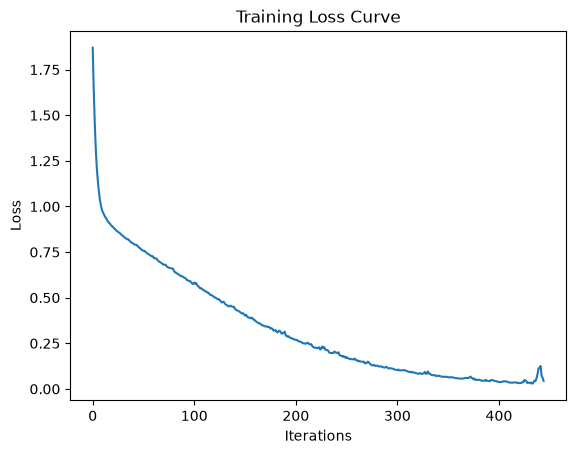

In [26]:
# Loss Curve
plt.plot(model.loss_curve_)
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.title("Training Loss Curve")
plt.show()